# 2015 — Knowledge Distillation

**Paper:** Geoffrey Hinton, Oriol Vinyals & Jeff Dean, *"Distilling the Knowledge in a Neural Network"* (2015). Earlier: Buciluă, Caruana & Niculescu-Mizil, *model compression* (2006).

A big **teacher** network's output probabilities hold more information than the label alone. For a handwritten "7", the teacher might say 90% "7", 8% "1", 1% "9". That says *which classes look alike*, what Hinton called **dark knowledge**. A small **student** trained to match these soft targets learns more from each example:

$$\mathcal L = \alpha\, T^2\, \mathrm{KL}\!\left(\operatorname{softmax}(z_t/T)\,\big\|\,\operatorname{softmax}(z_s/T)\right) + (1-\alpha)\,\mathrm{CE}(y, \operatorname{softmax}(z_s))$$

The **temperature** $T > 1$ softens both distributions so that the small probabilities matter; the $T^2$ factor keeps gradient sizes comparable.

Distillation is everywhere in 2024–2026: small LLMs (Gemma, Llama 3.2 1B/3B, DeepSeek-R1-Distill, Qwen small models) are trained on a big model's outputs or logits.

![Diagram: Knowledge distillation (Hinton, Vinyals & Dean, 2015)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/31_2015_knowledge_distillation.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors(size=16)]

## Teacher: a CNN trained on the full training set

In [3]:
teacher = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                        nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 16, 256), nn.ReLU(), nn.Linear(256, 10)).to(device)
opt = torch.optim.Adam(teacher.parameters(), lr=1e-3)
for s in range(1500):
    idx = torch.randint(0, len(Xtr), (64,), device=device)
    loss = F.cross_entropy(teacher(Xtr[idx]), ytr[idx]); opt.zero_grad(); loss.backward(); opt.step()
teacher.eval()
with torch.no_grad(): t_acc = (teacher(Xte).argmax(1) == yte).float().mean().item()
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"teacher: {n_params(teacher):,} parameters, test accuracy {t_acc:.3f}")

teacher: 320,714 parameters, test accuracy 0.981


## Dark knowledge
Softened teacher outputs ($T=4$) for a few test digits: the second-highest classes are digits that genuinely look similar.

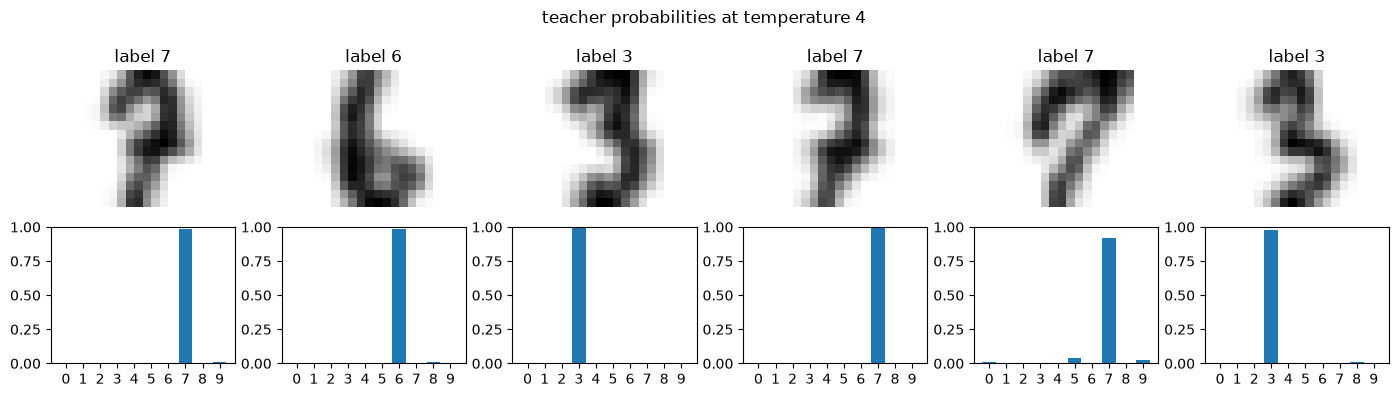

In [4]:
with torch.no_grad(): soft = F.softmax(teacher(Xte[:6]) / 4, -1).cpu()
fig, axes = plt.subplots(2, 6, figsize=(14, 4))
for j in range(6):
    axes[0, j].imshow(Xte[j, 0].cpu(), cmap="gray_r"); axes[0, j].axis("off"); axes[0, j].set_title(f"label {yte[j].item()}")
    axes[1, j].bar(range(10), soft[j]); axes[1, j].set_xticks(range(10)); axes[1, j].set_ylim(0, 1)
plt.suptitle("teacher probabilities at temperature 4"); plt.tight_layout(); plt.show()

## Student: a small MLP, with only 100 labelled examples
The student sees only 100 labelled images, plus the rest of the training images **without labels**. It is trained three ways:
1. hard labels only (100 examples)
2. distillation on the same 100 examples
3. distillation on all training images: labels aren't needed, because the teacher provides the targets

In [5]:
def student(): return nn.Sequential(nn.Flatten(), nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 10))
lab_idx = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(0))[:100].to(device)

def train_student(mode, T=4.0, alpha=0.9, steps=1500):
    seed_everything(0); s = student().to(device); opt = torch.optim.Adam(s.parameters(), lr=2e-3, weight_decay=1e-4)
    for _ in range(steps):
        if mode == "distill_all": idx = torch.randint(0, len(Xtr), (64,), device=device)
        else: idx = lab_idx[torch.randint(0, len(lab_idx), (64,), device=device)]
        x = Xtr[idx]; z_s = s(x)
        if mode == "hard":
            loss = F.cross_entropy(z_s, ytr[idx])
        else:
            with torch.no_grad(): z_t = teacher(x)
            kd = F.kl_div(F.log_softmax(z_s / T, -1), F.softmax(z_t / T, -1), reduction="batchmean") * T * T
            if mode == "distill_all": loss = kd                                            # no labels used at all
            else: loss = alpha * kd + (1 - alpha) * F.cross_entropy(z_s, ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad(): return (s(Xte).argmax(1) == yte).float().mean().item(), s

results = {m: train_student(m)[0] for m in ["hard", "distill", "distill_all"]}
print(f"student: {n_params(student()):,} parameters ({n_params(teacher) / n_params(student()):.0f}x smaller than the teacher)")
for k, name in [("hard", "hard labels, 100 examples"), ("distill", "distillation, 100 examples"), ("distill_all", "distillation, all images (no labels)")]:
    print(f"  {name:40s} test acc {results[k]:.3f}")
print(f"  {'teacher':40s} test acc {t_acc:.3f}")

student: 17,098 parameters (19x smaller than the teacher)
  hard labels, 100 examples                test acc 0.883
  distillation, 100 examples               test acc 0.928
  distillation, all images (no labels)     test acc 0.961
  teacher                                  test acc 0.981


## The effect of temperature

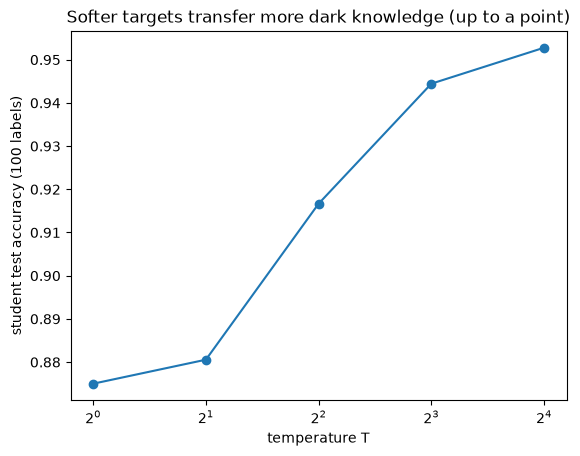

In [6]:
temps = [1, 2, 4, 8, 16]
accs = [train_student("distill", T=T, steps=800)[0] for T in temps]
plt.plot(temps, accs, marker="o"); plt.xscale("log", base=2); plt.xlabel("temperature T"); plt.ylabel("student test accuracy (100 labels)")
plt.title("Softer targets transfer more dark knowledge (up to a point)"); plt.show()